In [ ]:
import base64
import subprocess
from pathlib import Path
from kaggle_secrets import UserSecretsClient

secrets = UserSecretsClient()
token = secrets.get_secret("GITHUB_TOKEN")

username = "AnikMallick"
repo_name = "bn-proverbs-in-context"

repo_dir = Path("/kaggle/working") / repo_name

auth = base64.b64encode(
    f"{username}:{token}".encode()
).decode()

try:
    subprocess.run(
        [
            "git",
            "-c",
            f"http.https://github.com/.extraheader="
            f"AUTHORIZATION: basic {auth}",
            "clone",
            f"https://github.com/{username}/{repo_name}.git",
            str(repo_dir),
        ],
        check=True,
    )
finally:
    del token
    del auth

print("Repository cloned successfully.")

In [ ]:
%cd /kaggle/working/bn-proverbs-in-context

!pip install -e .

In [1]:
from pathlib import Path
from probad.utils import print_div
from probad.schema import TestItem, validate_items
import json
from typing import Any
import probad.builder as exp

DATA_PATH = Path("/kaggle/input/datasets/amallick0507/probad")

train_data = list(TestItem.load_items(DATA_PATH/"train.jsonl"))
test_data = list(TestItem.load_items(DATA_PATH/"test.jsonl"))
val_data = list(TestItem.load_items(DATA_PATH/"val.jsonl"))


source = DATA_PATH / "stopwords-bn.json"

try:
    data: Any = json.loads(source.read_text(encoding="utf-8-sig"))
except FileNotFoundError as exc:
    raise FileNotFoundError(f"Stopword file not found: {source}") from exc
except json.JSONDecodeError as exc:
    raise ValueError(
        f"Invalid JSON in stopword file {source}: "
        f"line {exc.lineno}, column {exc.colno}: {exc.msg}"
    ) from exc

BN_STOPWORDS =  frozenset([word.strip() for word in data])

print_div("train")
for issue in validate_items(train_data, BN_STOPWORDS):
    print(issue)

print_div("test")
for issue in validate_items(test_data, BN_STOPWORDS):
    print(issue)

print_div("val")
for issue in validate_items(val_data, BN_STOPWORDS):
    print(issue)

=============================================> train <==============================================
==============================================> test <==============================================
[WARNING] prv_088_1: en.correct_echoes_gloss: correct option reuses many literal-gloss words
[WARNING] prv_088_2: en.correct_echoes_gloss: correct option reuses many literal-gloss words
==============================================> val <===============================================


In [2]:
from kaggle_secrets import UserSecretsClient
import os
from probad.scoring import LoadBalancedModel

user_secrets = UserSecretsClient()
secret_value_1 = user_secrets.get_secret("HF_TOKEN")
os.environ['HF_TOKEN'] = secret_value_1

MODEL_NAME = "allenai/OLMo-2-0425-1B"
model = LoadBalancedModel(
    MODEL_NAME,
    gpu_ids=(0, 1)
)

tok = model.tok

config.json:   0%|          | 0.00/623 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.34k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.14M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/14.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/179 [00:00<?, ?it/s]

In [22]:
import pandas as pd


## E1 Experiment
Knowing: can the model finish the proverb when the last word is removed?

In [25]:
from probad.scoring import answer_one, generate, check_memorisation, check_memorisation_graded
from probad.builder import MEM_TEMPLATES


In [14]:
unique_test_data = {}
for t in test_data:
    if t.proverb.proverb_id not in unique_test_data:
        unique_test_data[t.proverb.proverb_id] = t

In [29]:
from itertools import product
from concurrent.futures import ThreadPoolExecutor, as_completed


def process_item(it, render, template):
    pid = it.proverb.proverb_id
    built = exp.e1_memorisation(it.model_dump(), render, template)

    if built is None:
        return None

    prompt, target = built
    output = generate(model, tok, prompt, 4)

    return {
        "model": MODEL_NAME,
        "proverb_id": pid,
        "render": render,
        "template": template,
        "prompt": prompt,
        "target": target,
        "output": output,
        "correct": check_memorisation(output, target),
        "correct_score": check_memorisation_graded(output, target),
        "label": "e1_memorisation",
        "variant": f"e1_memorisation(it, {render}, {template})",
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in unique_test_data.values():
        for render, template in product(["bengali", "english"], [0, 1, 2, 3, 4]):
            e1_futures.append(executor.submit(process_item, item, render, template))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [30]:
e1_results_df = pd.DataFrame(results)
e1_results_df.head(2)

,model,proverb_id,render,template,prompt,target,output,correct,correct_score,label,variant
0,allenai/OLMo-2-0425-1B,prv_001,bengali,1,এই প্রবাদটি সম্পূর্ণ করো: অতি লোভে তাঁতি,নষ্ট,কর�,False,0.0,e1_memorisation,"e1_memorisation(it, bengali, 1)"
1,allenai/OLMo-2-0425-1B,prv_001,bengali,0,প্রবাদ: অতি লোভে তাঁতি,নষ্ট,করে,False,0.0,e1_memorisation,"e1_memorisation(it, bengali, 0)"


In [31]:
e1_results_df.shape

(2000, 11)

In [32]:
sum(e1_results_df["correct"])

24

In [33]:
e1_results_df["correct_score"].mean()

np.float64(0.22075348883142998)

## E2 Experiment
Using: pick the right meaning in a conversation MAPS style

In [34]:
def item_info(it):
    return {"item_id": it["item_id"], "proverb_id": it["proverb"]["proverb_id"],
            "figurative": it["proverb"]["figurative"], "split": it["meta"]["split"],
            "subsets": it["meta"].get("subsets", [])}

In [35]:
def process_item(item):
    r = exp.e2_reasoning(item.model_dump())

    return {
        "model": MODEL_NAME,
        "label": "e2_reasoning",
        "variant": "exp.e2_reasoning(item.model_dump())",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }


results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [36]:
e2_results_df = pd.DataFrame(results)
e2_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.885631,0.114369,2.046875,0.934602
1,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_2,prv_001,True,test,[maps_overlap],a,a,True,0.810479,0.189521,1.453125,0.911948


In [37]:
sum(e2_results_df["correct"])

294

## E2 Literals

In [38]:
def process_item(item):
    r = exp.e2_reasoning(item.model_dump(), keys=("correct", "literal"))

    return {
        "model": MODEL_NAME,
        "label": "e2_reasoning",
        "variant": "exp.e2_reasoning(item.model_dump())",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }


results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [39]:
e2_lit_results_df = pd.DataFrame(results)
e2_lit_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.836555,0.163445,1.632812,0.930090
1,allenai/OLMo-2-0425-1B,e2_reasoning,exp.e2_reasoning(item.model_dump()),prv_001_2,prv_001,True,test,[maps_overlap],a,a,True,0.801315,0.198685,1.394531,0.929326


In [40]:
sum(e2_lit_results_df["correct"])

294

## E3 and E4
Knowing vs using: E2 accuracy for memorised vs not-memorised proverbs

In [43]:
def e3_knowing_vs_using(e1_df, e2_df, render="bengali"):
    """E3: is accuracy higher on proverbs the model has memorised?
    memorised = any template completes the proverb (MAPS rule)."""
    mem = (e1_df[e1_df["render"] == render]
           .groupby("proverb_id")["correct"].any().rename("memorised"))
    item = e2_df.groupby(["item_id", "proverb_id"])["correct"].mean().reset_index()  # collapses option orders
    df = item.merge(mem, on="proverb_id", how="left").fillna({"memorised": False})
    df["memorised"] = df["memorised"].astype(bool)
    df["used"] = df["correct"] >= 0.5
    df["quadrant"] = df["memorised"].map({True: "know", False: "dont_know"}) + "+" + \
                     df["used"].map({True: "use", False: "dont_use"})
    acc = df.groupby("memorised")["correct"].agg(acc="mean", n="size")
    quad = df["quadrant"].value_counts()
    return acc, quad, df


def e4_figurative(e2_df):
    """E4: accuracy on figurative vs non-figurative proverbs."""
    item = e2_df.groupby(["item_id", "figurative"])["correct"].mean().reset_index()
    return item.groupby("figurative")["correct"].agg(acc="mean", n="size")

In [52]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="bengali")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="bengali")
display(acc); print(quad)
display(acc_lit); print(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


,acc,n
memorised,,
False,0.485470,585
True,0.666667,15


quadrant
dont_know+dont_use    301
dont_know+use         284
know+use               10
know+dont_use           5
Name: count, dtype: int64


,acc,n
memorised,,
False,0.485470,585
True,0.666667,15


quadrant
dont_know+dont_use    301
dont_know+use         284
know+use               10
know+dont_use           5
Name: count, dtype: int64


,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


In [53]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="english")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="english")
display(acc); print(quad)
display(acc_lit); print(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

,acc,n
memorised,,
False,0.483761,585
True,0.733333,15


quadrant
dont_know+dont_use    302
dont_know+use         283
know+use               11
know+dont_use           4
Name: count, dtype: int64


,acc,n
memorised,,
False,0.483761,585
True,0.733333,15


quadrant
dont_know+dont_use    302
dont_know+use         283
know+use               11
know+dont_use           4
Name: count, dtype: int64


,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


## E5 - control

In [54]:
def process_item(item):
    r = exp.e5_control(item.model_dump())

    return {
        "model": MODEL_NAME,
        "label": "e5_control",
        "variant": "exp.e5_control(item.model_dump())",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }


results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [55]:
e5_control_results_df = pd.DataFrame(results)
e5_control_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e5_control,exp.e5_control(item.model_dump()),prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.933431,0.066569,2.640625,0.931544
1,allenai/OLMo-2-0425-1B,e5_control,exp.e5_control(item.model_dump()),prv_001_2,prv_001,True,test,[maps_overlap],a,a,True,0.898411,0.101589,2.179687,0.911197


In [56]:
sum(e5_control_results_df["correct"])

294

## E5 - negation

In [63]:
def process_item(item, question):
    r = exp.e5_negated(item.model_dump(), question=question) #"neg", "neg1", "neg2", "neg3", "neg4"

    return {
        "model": MODEL_NAME,
        "label": "e5_negated",
        "variant": f"exp.e5_negated(item.model_dump(), {question})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["neg", "neg1", "neg2", "neg3", "neg4"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [64]:
e5_negated_results_df = pd.DataFrame(results)
e5_negated_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e5_negated,"exp.e5_negated(item.model_dump(), neg)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.874935,0.125065,-1.945312,0.935476
1,allenai/OLMo-2-0425-1B,e5_negated,"exp.e5_negated(item.model_dump(), neg1)",prv_001_1,prv_001,True,test,[maps_overlap],b,a,False,0.835215,0.164785,-1.623047,0.961100


In [68]:
sum(e5_negated_results_df["correct"])

1530

## E6

In [69]:
def process_item(item, condition):
    r = exp.e6_translation(item.model_dump(), condition=condition)

    return {
        "model": MODEL_NAME,
        "label": "e6_translation",
        "variant": f"exp.e6_translation(item.model_dump(), {condition})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in ["bn_native", "en_romanised", "en_gloss"]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [70]:
e6_results_df = pd.DataFrame(results)
e6_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e6_translation,"exp.e6_translation(item.model_dump(), en_roman...",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.852935,0.147065,1.757812,0.975262
1,allenai/OLMo-2-0425-1B,e6_translation,"exp.e6_translation(item.model_dump(), bn_native)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.885631,0.114369,2.046875,0.934602


In [71]:
sum(e6_results_df["correct"])

888

## E7

In [72]:
fewshot = [v.model_dump() for v in val_data]
def process_item(item):
    k = 3
    r = exp.e7_few_shot(item.model_dump(), demo_items=fewshot, k=k)

    return {
        "model": MODEL_NAME,
        "label": "e7_few_shot",
        "variant": f"exp.e7_few_shot(item.model_dump(), fewshot, {k})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    futures = [
        executor.submit(process_item, item)
        for item in test_data
    ]

    for future in as_completed(futures):
        results.append(future.result())

In [73]:
e7_results_df = pd.DataFrame(results)
e7_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e7_few_shot,"exp.e7_few_shot(item.model_dump(), fewshot, 3)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.716417,0.283583,0.926758,0.987146
1,allenai/OLMo-2-0425-1B,e7_few_shot,"exp.e7_few_shot(item.model_dump(), fewshot, 3)",prv_001_2,prv_001,True,test,[maps_overlap],a,a,True,0.681303,0.318697,0.759766,0.988174


In [74]:
sum(e7_results_df["correct"])

290

## E9

In [75]:
def process_item(item, template):
    r = exp.e9_template(item.model_dump(), template=template)

    return {
        "model": MODEL_NAME,
        "label": "e9_template",
        "variant": f"exp.e9_template(item.model_dump(), {template})",
        **item_info(item.model_dump()),
        **answer_one(
            model, tok,
            r[0], r[1], r[2],
            system=None,
            chat=False
        )
    }



results = []

with ThreadPoolExecutor(max_workers=2) as executor:
    e1_futures = []
    for item in test_data:
        for q in [1, 2, 3]:
            e1_futures.append(executor.submit(process_item, item, q))
    for future in as_completed(e1_futures):
        results.append(future.result())

In [76]:
e9_results_df = pd.DataFrame(results)
e9_results_df.head(2)

,model,label,variant,item_id,proverb_id,figurative,split,subsets,gold,pred,correct,p_a,p_b,margin,letter_mass
0,allenai/OLMo-2-0425-1B,e9_template,"exp.e9_template(item.model_dump(), 1)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.900617,0.099383,2.204102,0.005953
1,allenai/OLMo-2-0425-1B,e9_template,"exp.e9_template(item.model_dump(), 2)",prv_001_1,prv_001,True,test,[maps_overlap],a,a,True,0.848596,0.151404,1.723633,0.985135


In [77]:
sum(e9_results_df["correct"])

882

In [80]:
OUT = Path("/kaggle/working/results_maps_alligned")
os.mkdir(OUT)

In [82]:
e1_results_df.to_csv(OUT / "e1_results_df.csv", index=False)
e2_results_df.to_csv(OUT / "e2_results_df.csv", index=False)
e2_lit_results_df.to_csv(OUT / "e2_lit_results_df.csv", index=False)
e5_control_results_df.to_csv(OUT / "e5_control_results_df.csv", index=False)
e5_negated_results_df.to_csv(OUT / "e5_negated_results_df.csv", index=False)
e6_results_df.to_csv(OUT / "e6_results_df.csv", index=False)
e7_results_df.to_csv(OUT / "e7_results_df.csv", index=False)
e9_results_df.to_csv(OUT / "e9_results_df.csv", index=False)

In [83]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="bengali")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="bengali")
display(acc); display(quad)
display(acc_lit); display(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

,acc,n
memorised,,
False,0.485470,585
True,0.666667,15


quadrant
dont_know+dont_use    301
dont_know+use         284
know+use               10
know+dont_use           5
Name: count, dtype: int64

,acc,n
memorised,,
False,0.485470,585
True,0.666667,15


quadrant
dont_know+dont_use    301
dont_know+use         284
know+use               10
know+dont_use           5
Name: count, dtype: int64

,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


In [84]:
acc.to_csv(OUT / "e3_acc_bengali_df.csv", index=False)
quad.to_csv(OUT / "e3_quad_bengali_df.csv", index=False)
e3_df.to_csv(OUT / "e3_results_bengali_df.csv", index=False)

acc_lit.to_csv(OUT / "e3_acc_bengali_lit_df.csv", index=False)
quad_lit.to_csv(OUT / "e3_quad_bengali_lit_df.csv", index=False)

e4_figurative(e2_results_df).to_csv(OUT / "e4_figurative_bengali_df.csv", index=False)
e4_figurative(e2_lit_results_df).to_csv(OUT / "e4_figurative_bengali_lit_df.csv", index=False)

In [85]:
acc, quad, e3_df = e3_knowing_vs_using(e1_results_df, e2_results_df, render="english")
acc_lit, quad_lit, _ = e3_knowing_vs_using(e1_results_df, e2_lit_results_df, render="english")
display(acc); display(quad)
display(acc_lit); display(quad_lit)

display(e4_figurative(e2_results_df))
display(e4_figurative(e2_lit_results_df))

,acc,n
memorised,,
False,0.483761,585
True,0.733333,15


quadrant
dont_know+dont_use    302
dont_know+use         283
know+use               11
know+dont_use           4
Name: count, dtype: int64

,acc,n
memorised,,
False,0.483761,585
True,0.733333,15


quadrant
dont_know+dont_use    302
dont_know+use         283
know+use               11
know+dont_use           4
Name: count, dtype: int64

,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


,acc,n
figurative,,
False,0.400000,90
True,0.505882,510


In [88]:
acc.to_csv(OUT / "e3_acc_english_df.csv", index=False)
quad.to_csv(OUT / "e3_quad_english_df.csv", index=False)
e3_df.to_csv(OUT / "e3_results_english_df.csv", index=False)

acc_lit.to_csv(OUT / "e3_acc_english_lit_df.csv", index=False)
quad_lit.to_csv(OUT / "e3_quad_english_lit_df.csv", index=False)

e4_figurative(e2_results_df).to_csv(
    OUT / "e4_figurative_english_df.csv", index=False
)
e4_figurative(e2_lit_results_df).to_csv(
    OUT / "e4_figurative_english_lit_df.csv", index=False
)

## Analysis

In [90]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

FIG = OUT / "figs"; FIG.mkdir(parents=True, exist_ok=True)

def item_level(df, by=("label",)):
    """Collapse option orders: one row per item (correct = share of orders right)."""
    df = df.copy()
    df["p_gold"] = df.apply(lambda r: r[f"p_{r['gold'].lower()}"], axis=1)
    df["n_opts"] = df.filter(regex=r"^p_[abc]$").notna().sum(axis=1)
    keys = [k for k in dict.fromkeys([*by, "item_id", "proverb_id", "figurative"]) if k in df]
    return df.groupby(keys, dropna=False).agg(
        correct=("correct", "mean"), p_gold=("p_gold", "mean"), margin=("margin", "mean"),
        letter_mass=("letter_mass", "mean"), n_opts=("n_opts", "first")).reset_index()

def ci(values, clusters, n=2000, seed=0):
    """95% CI of the mean, resampling whole proverbs."""
    _, inv = np.unique(np.asarray(clusters), return_inverse=True)
    s, c = np.bincount(inv, np.asarray(values, float)), np.bincount(inv)
    pick = np.random.default_rng(seed).integers(0, len(c), (n, len(c)))
    return np.percentile(s[pick].sum(1) / c[pick].sum(1), [2.5, 97.5])

def summary(df, name, by="label"):
    it = item_level(df, (by,))
    rows = []
    for key, g in it.groupby(by):
        lo, hi = ci(g["correct"], g["proverb_id"])
        raw = df[df[by] == key]
        rows.append({"exp": name, by: key, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi,
                     "chance": 1 / g["n_opts"].mean(), "n": len(g),
                     "p_gold": g["p_gold"].mean(), "letter_mass": g["letter_mass"].median(),
                     "pred_a": (raw["pred"].str.lower() == "a").mean(),            # position bias
                     "acc_gold_a": raw.loc[raw["gold"].str.lower() == "a", "correct"].mean(),
                     "acc_gold_b": raw.loc[raw["gold"].str.lower() == "b", "correct"].mean()})
    return pd.DataFrame(rows)

def paired(a, b, name_a, name_b):
    """b - a on shared items, CI over proverbs, McNemar counts."""
    m = item_level(a, ()).merge(item_level(b, ()), on=["item_id", "proverb_id"], suffixes=("_a", "_b"))
    d = m["correct_b"] - m["correct_a"]
    lo, hi = ci(d, m["proverb_id"])
    return {"a": name_a, "b": name_b, "acc_a": m["correct_a"].mean(), "acc_b": m["correct_b"].mean(),
            "diff": d.mean(), "ci_lo": lo, "ci_hi": hi, "a_only": int((d < 0).sum()),
            "b_only": int((d > 0).sum()), "n": len(m)}

def bar(tab, title, fname, x="label"):
    fig, ax = plt.subplots(figsize=(max(4, 0.9 * len(tab) + 2), 3.5))
    ax.bar(tab[x].astype(str), tab["acc"], yerr=[tab["acc"] - tab["ci_lo"], tab["ci_hi"] - tab["acc"]],
           capsize=4, color="#4C72B0")
    for i, c in enumerate(tab["chance"]):
        ax.hlines(c, i - 0.4, i + 0.4, colors="red", linestyles="--")
    ax.set_ylim(0, 1); ax.set_ylabel("accuracy"); ax.set_title(title)
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); fig.savefig(FIG / fname, dpi=150); plt.show()

,exp,label,acc,ci_lo,ci_hi,chance,n,p_gold,letter_mass,pred_a,acc_gold_a,acc_gold_b,cond
0,E2,e2_reasoning,0.490,0.448,0.530,0.5,600,0.489,0.903,1.000,1.000,0.000,E2:e2_reasoning
1,E2_lit,e2_reasoning,0.490,0.448,0.530,0.5,600,0.495,0.899,1.000,1.000,0.000,E2_lit:e2_reasoning
2,E5_neg,e5_negated,0.510,0.470,0.552,0.5,600,0.512,0.933,1.000,1.000,0.000,E5_neg:e5_negated
3,E5_control,e5_control,0.490,0.448,0.530,0.5,600,0.490,0.929,1.000,1.000,0.000,E5_control:e5_control
4,E6,e6_translation,0.493,0.453,0.533,0.5,600,0.506,0.932,0.993,0.997,0.010,E6:e6_translation
5,E7,e7_few_shot,0.483,0.443,0.523,0.5,600,0.492,0.983,0.957,0.949,0.036,E7:e7_few_shot
6,E9,e9_template,0.490,0.448,0.530,0.5,600,0.490,0.633,1.000,1.000,0.000,E9:e9_template


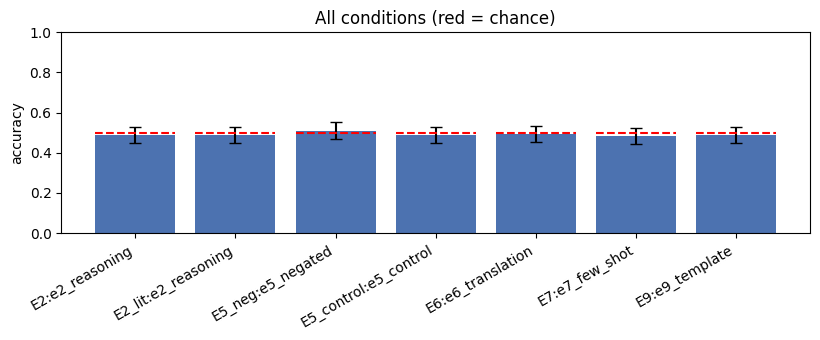

In [93]:
# all MCQ conditions in one table
runs = {"E2": e2_results_df, "E2_lit": e2_lit_results_df, "E5_neg": e5_negated_results_df,
        "E5_control": e5_control_results_df, "E6": e6_results_df, "E7": e7_results_df, "E9": e9_results_df}
overview = pd.concat([summary(df, name) for name, df in runs.items()], ignore_index=True)
overview["cond"] = overview["exp"] + ":" + overview["label"].astype(str)
overview.to_csv(OUT / "overview.csv", index=False)
display(overview.round(3))
bar(overview, "All conditions (red = chance)", "overview.png", x="cond")

E1 per template
 render    bengali  english
template                  
0           0.010    0.005
1           0.005    0.015
2           0.005    0.015
3           0.015    0.015
4           0.020    0.015
E1 memorised (any template)
           mean  size
render              
bengali  0.025   200
english  0.025   200


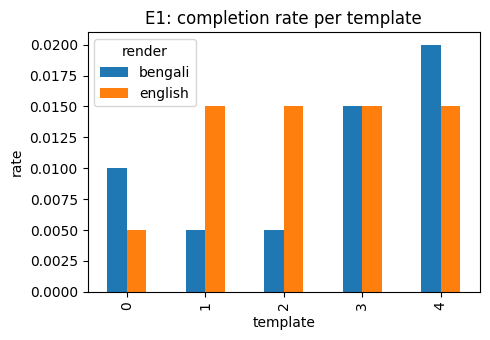

In [94]:
# E1 memorisation
mem_t = e1_results_df.groupby(["render", "template"])["correct"].mean().unstack("render")
mem_any = e1_results_df.groupby(["render", "proverb_id"])["correct"].any().groupby("render").agg(["mean", "size"])
print("E1 per template\n", mem_t.round(3)); print("E1 memorised (any template)\n", mem_any.round(3))
mem_t.plot.bar(figsize=(5, 3.5), title="E1: completion rate per template", ylabel="rate")
plt.tight_layout(); plt.savefig(FIG / "e1_templates.png", dpi=150); plt.show()

In [95]:
# E3 knowing vs using
def e3(e2_df, render):
    mem = e1_results_df[e1_results_df["render"] == render].groupby("proverb_id")["correct"].any().rename("memorised")
    it = item_level(e2_df, ()).merge(mem, on="proverb_id", how="left").fillna({"memorised": False})
    it["memorised"] = it["memorised"].astype(bool)
    it["used"] = it["correct"] >= 0.5
    rows = []
    for m, g in it.groupby("memorised"):
        lo, hi = ci(g["correct"], g["proverb_id"])
        rows.append({"render": render, "memorised": m, "acc": g["correct"].mean(), "ci_lo": lo, "ci_hi": hi, "n": len(g)})
    quad = pd.crosstab(it["memorised"].map({True: "knows", False: "doesn't know"}),
                       it["used"].map({True: "uses", False: "doesn't use"}))
    return pd.DataFrame(rows), quad, it

E2 bengali 
 used          doesn't use  uses
memorised                      
doesn't know          301   284
knows                   5    10
E2 english 
 used          doesn't use  uses
memorised                      
doesn't know          302   283
knows                   4    11
E2_lit bengali 
 used          doesn't use  uses
memorised                      
doesn't know          301   284
knows                   5    10
E2_lit english 
 used          doesn't use  uses
memorised                      
doesn't know          302   283
knows                   4    11


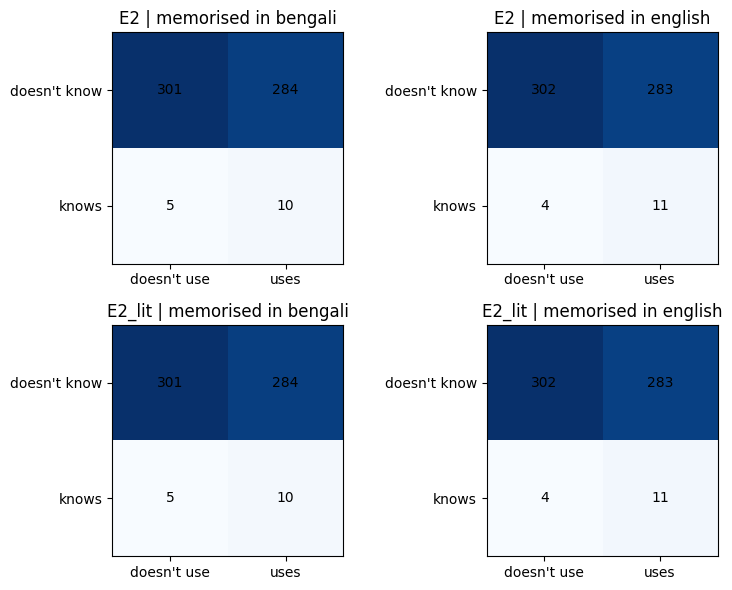

    render  memorised    acc  ci_lo  ci_hi    n     exp
0  bengali      False  0.485  0.446  0.526  585      E2
1  bengali       True  0.667  0.667  0.667   15      E2
2  english      False  0.484  0.441  0.523  585      E2
3  english       True  0.733  0.667  0.867   15      E2
4  bengali      False  0.485  0.446  0.526  585  E2_lit
5  bengali       True  0.667  0.667  0.667   15  E2_lit
6  english      False  0.484  0.441  0.523  585  E2_lit
7  english       True  0.733  0.667  0.867   15  E2_lit


In [96]:
e3_tabs, fig, axes = [], *plt.subplots(2, 2, figsize=(8, 6))
for i, (name, df) in enumerate({"E2": e2_results_df, "E2_lit": e2_lit_results_df}.items()):
    for j, render in enumerate(e1_results_df["render"].unique()[:2]):
        acc_, quad_, _ = e3(df, render)
        e3_tabs.append(acc_.assign(exp=name)); print(name, render, "\n", quad_)
        ax = axes[i, j]; ax.imshow(quad_.values, cmap="Blues")
        for (r, c), v in np.ndenumerate(quad_.values):
            ax.text(c, r, v, ha="center", va="center")
        ax.set_xticks(range(quad_.shape[1]), quad_.columns); ax.set_yticks(range(quad_.shape[0]), quad_.index)
        ax.set_title(f"{name} | memorised in {render}")
plt.tight_layout(); fig.savefig(FIG / "e3_quadrants.png", dpi=150); plt.show()
e3_tab = pd.concat(e3_tabs, ignore_index=True); e3_tab.to_csv(OUT / "e3_knowing_vs_using.csv", index=False)
print(e3_tab.round(3).to_string())

      exp  figurative    acc  ci_lo  ci_hi  chance    n  p_gold  letter_mass  pred_a  acc_gold_a  acc_gold_b
0      E2       False  0.400  0.300  0.511     0.5   90   0.434        0.889     1.0         1.0         0.0
1      E2        True  0.506  0.463  0.547     0.5  510   0.499        0.905     1.0         1.0         0.0
2  E2_lit       False  0.400  0.300  0.511     0.5   90   0.432        0.885     1.0         1.0         0.0
3  E2_lit        True  0.506  0.463  0.547     0.5  510   0.507        0.901     1.0         1.0         0.0


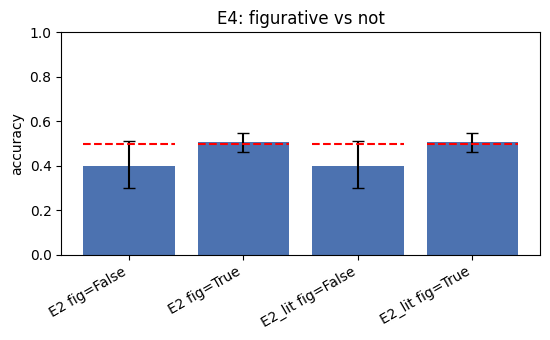

In [97]:
# E4 figurative
e4_tab = pd.concat([summary(df, name, by="figurative") for name, df in
                    {"E2": e2_results_df, "E2_lit": e2_lit_results_df}.items()], ignore_index=True)
e4_tab.to_csv(OUT / "e4_figurative.csv", index=False); print(e4_tab.round(3).to_string())
bar(e4_tab.assign(cond=e4_tab["exp"] + " fig=" + e4_tab["figurative"].astype(str)), "E4: figurative vs not", "e4.png", x="cond")

In [99]:
# E5 does the model read the question?
neg = item_level(e5_negated_results_df)
pos = item_level(e2_results_df, ())[["item_id", "correct"]].rename(columns={"correct": "pos"})
e5_tab = []
for q, g in neg.groupby("label"):
    m = g.merge(pos, on="item_id")
    # 2 options: in the negated prompt, "not correct" means the model picked the correct meaning
    m["same_choice"] = (m["pos"] >= 0.5) == (m["correct"] < 0.5)
    e5_tab.append({"question": q, "acc_pos": m["pos"].mean(), "acc_neg": m["correct"].mean(),
                   "sum": m["pos"].mean() + m["correct"].mean(),   # ~1.0 = ignores the question
                   "same_option_both": m["same_choice"].mean(), "n": len(m)})
e5_tab = pd.DataFrame(e5_tab); e5_tab.to_csv(OUT / "e5_negation.csv", index=False); display(e5_tab.round(3))
print("no-question control vs E2:", paired(e5_control_results_df, e2_results_df, "control", "E2"))

,question,acc_pos,acc_neg,sum,same_option_both,n
0,e5_negated,0.49,0.51,1.0,1.0,600


no-question control vs E2: {'a': 'control', 'b': 'E2', 'acc_a': np.float64(0.49), 'acc_b': np.float64(0.49), 'diff': np.float64(0.0), 'ci_lo': np.float64(0.0), 'ci_hi': np.float64(0.0), 'a_only': 0, 'b_only': 0, 'n': 600}


,exp,a,b,acc_a,acc_b,diff,ci_lo,ci_hi,a_only,b_only,n
0,E6,E2,e6_translation,0.49,0.493,0.003,-0.001,0.008,2,9,600
1,E7,E2,e7_few_shot,0.49,0.483,-0.007,-0.023,0.012,15,11,600
2,E9,E2,e9_template,0.49,0.490,0.000,0.000,0.000,0,0,600


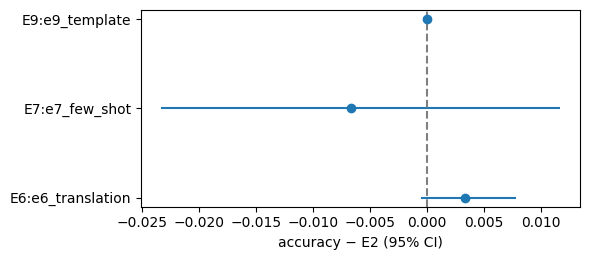

In [101]:
# E6 / E7 / E9 vs E2 (paired)
diffs = []
for name, df in {"E6": e6_results_df, "E7": e7_results_df, "E9": e9_results_df}.items():
    for lab, g in df.groupby("label"):
        diffs.append({"exp": name, **paired(e2_results_df, g, "E2", lab)})
diffs = pd.DataFrame(diffs); diffs.to_csv(OUT / "paired_vs_e2.csv", index=False); display(diffs.round(3))
fig, ax = plt.subplots(figsize=(6, 0.4 * len(diffs) + 1.5))
ax.errorbar(diffs["diff"], range(len(diffs)), xerr=[diffs["diff"] - diffs["ci_lo"], diffs["ci_hi"] - diffs["diff"]], fmt="o")
ax.axvline(0, color="grey", ls="--"); ax.set_yticks(range(len(diffs)), diffs["exp"] + ":" + diffs["b"].astype(str))
ax.set_xlabel("accuracy − E2 (95% CI)"); plt.tight_layout(); fig.savefig(FIG / "paired_vs_e2.png", dpi=150); plt.show()

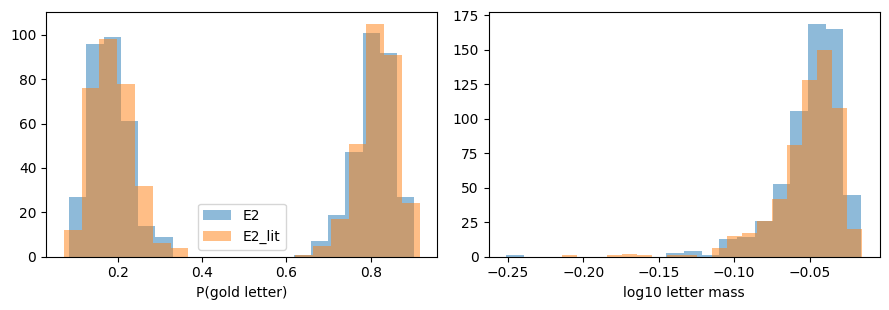

       item_id proverb_id  figurative  correct    p_gold    margin  letter_mass  n_opts  correct_lit
44   prv_018_3    prv_018        True      0.0  0.084493 -2.382813     0.914163       2          0.0
276  prv_123_1    prv_123        True      0.0  0.086323 -2.359375     0.899456       2          0.0
584  prv_253_3    prv_253        True      0.0  0.086632 -2.355469     0.938351       2          0.0
215  prv_096_3    prv_096        True      0.0  0.099121 -2.207031     0.937708       2          0.0
229  prv_103_2    prv_103        True      0.0  0.099295 -2.205078     0.940993       2          0.0
72   prv_033_1    prv_033        True      0.0  0.100172 -2.195313     0.931650       2          0.0
320  prv_139_3    prv_139       False      0.0  0.100172 -2.195313     0.905289       2          0.0
443  prv_188_3    prv_188        True      0.0  0.100172 -2.195312     0.900733       2          0.0
157  prv_073_2    prv_073        True      0.0  0.103567 -2.158203     0.938016       2    

In [102]:
# confidence / letter mass
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, df in {"E2": e2_results_df, "E2_lit": e2_lit_results_df}.items():
    it = item_level(df, ())
    axes[0].hist(it["p_gold"], bins=20, alpha=0.5, label=name)
    axes[1].hist(np.log10(it["letter_mass"]), bins=20, alpha=0.5, label=name)
axes[0].set_xlabel("P(gold letter)"); axes[1].set_xlabel("log10 letter mass")
axes[0].legend(); plt.tight_layout(); fig.savefig(FIG / "confidence.png", dpi=150); plt.show()

# hardest items (for error analysis)
hard = item_level(e2_results_df, ()).merge(item_level(e2_lit_results_df, ())[["item_id", "correct"]],
                                           on="item_id", suffixes=("", "_lit"))
hard = hard.sort_values(["correct", "correct_lit", "p_gold"]).head(30)
hard.to_csv(OUT / "hardest_items.csv", index=False); print(hard.head(10).to_string())

In [107]:
!zip -r /kaggle/working/probad_maps_E1_to_E7andE9_kaggle_results.zip /kaggle/working/results_maps_alligned

  adding: kaggle/working/results_maps_alligned/ (stored 0%)
  adding: kaggle/working/results_maps_alligned/e1_results_df.csv (deflated 92%)
  adding: kaggle/working/results_maps_alligned/e4_figurative_bengali_lit_df.csv (stored 0%)
  adding: kaggle/working/results_maps_alligned/e4_figurative_bengali_df.csv (stored 0%)
  adding: kaggle/working/results_maps_alligned/e9_results_df.csv (deflated 79%)
  adding: kaggle/working/results_maps_alligned/hardest_items.csv (deflated 61%)
  adding: kaggle/working/results_maps_alligned/e4_figurative.csv (deflated 55%)
  adding: kaggle/working/results_maps_alligned/e4_figurative_english_df.csv (stored 0%)
  adding: kaggle/working/results_maps_alligned/e2_results_df.csv (deflated 79%)
  adding: kaggle/working/results_maps_alligned/e3_acc_english_lit_df.csv (deflated 38%)
  adding: kaggle/working/results_maps_alligned/e3_acc_bengali_lit_df.csv (deflated 40%)
  adding: kaggle/working/results_maps_alligned/e7_results_df.csv (deflated 81%)
  adding: kaggle